In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, plot_tree

import warnings
warnings.filterwarnings('ignore')

In [45]:

np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

In [46]:
df = pd.DataFrame()

In [47]:

df['X'] = X.reshape(100)
df['y'] = y


In [48]:
df

,X,y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986
...,...,...
95,-0.006204,-0.040675
96,0.022733,-0.002305
97,-0.072459,0.032809
98,-0.474581,0.689516


Text(0.5, 1.0, 'X vs Y')

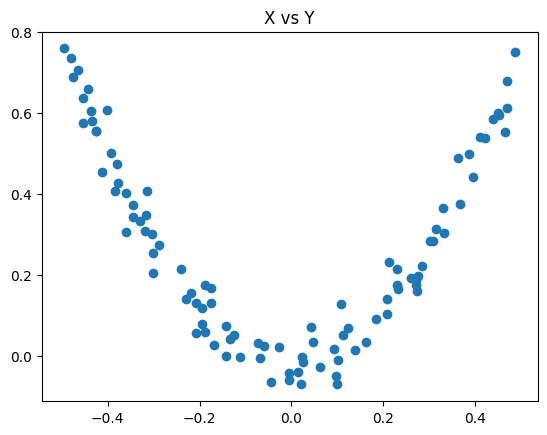

In [51]:

plt.scatter(df['X'],df['y'])
plt.title('X vs Y')


In [52]:
df['pred1'] = df['y'].mean()

In [35]:
dt1 = DecisionTreeRegressor(max_leaf_nodes=8)
dt1.fit(df[['X']], df['res_1'])

DecisionTreeRegressor(max_leaf_nodes=8)

In [53]:
df

,X,y,pred1
0,-0.125460,0.051573,0.265458
1,0.450714,0.594480,0.265458
2,0.231994,0.166052,0.265458
3,0.098658,-0.070178,0.265458
4,-0.343981,0.343986,0.265458
...,...,...,...
95,-0.006204,-0.040675,0.265458
96,0.022733,-0.002305,0.265458
97,-0.072459,0.032809,0.265458
98,-0.474581,0.689516,0.265458


In [54]:

df['res1'] = df['y'] - df['pred1']
df

,X,y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407
3,0.098658,-0.070178,0.265458,-0.335636
4,-0.343981,0.343986,0.265458,0.078528
...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133
96,0.022733,-0.002305,0.265458,-0.267763
97,-0.072459,0.032809,0.265458,-0.232650
98,-0.474581,0.689516,0.265458,0.424057


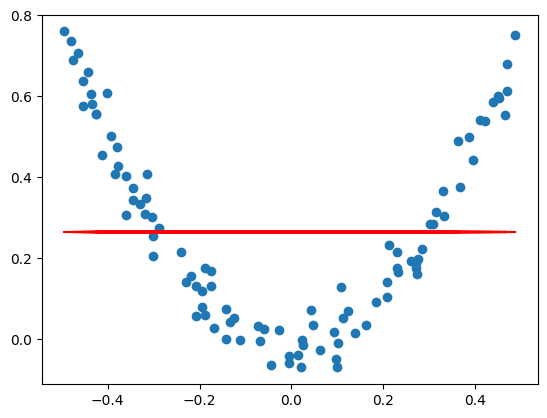

In [55]:
plt.scatter(df['X'],df['y'])
plt.plot(df['X'],df['pred1'],color='red')

In [66]:
dt1 = DecisionTreeRegressor(max_leaf_nodes=10)
dt1.fit(df[['X']], df['res1'])

DecisionTreeRegressor(max_leaf_nodes=10)

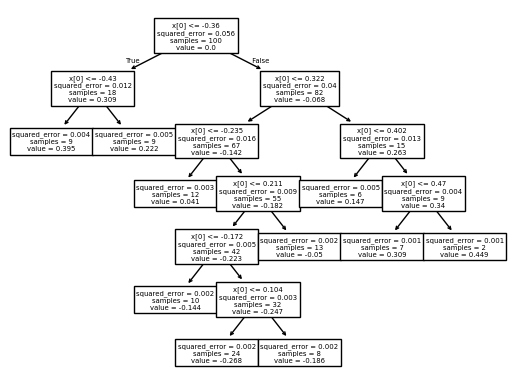

In [67]:
plot_tree(dt1)
plt.show()

In [70]:
# Generate X_test
X_test = np.linspace(-0.5, 0.5, 100).reshape(-1, 1)

# Predict y_test
y_pred = 0.265458 + dt1.predict(X_test)

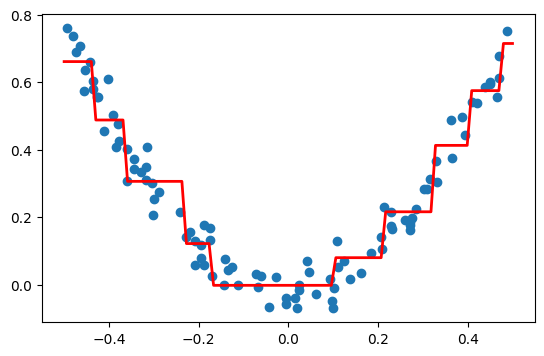

In [71]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])

In [73]:
df['pred2'] = 0.265458 + dt1.predict(df['X'].values.reshape(100,1))
df

,X,y,pred1,res1,pred2
0,-0.125460,0.051573,0.265458,-0.213885,-0.002160
1,0.450714,0.594480,0.265458,0.329021,0.574829
2,0.231994,0.166052,0.265458,-0.099407,0.215784
3,0.098658,-0.070178,0.265458,-0.335636,-0.002160
4,-0.343981,0.343986,0.265458,0.078528,0.305964
...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.002160
96,0.022733,-0.002305,0.265458,-0.267763,-0.002160
97,-0.072459,0.032809,0.265458,-0.232650,-0.002160
98,-0.474581,0.689516,0.265458,0.424057,0.660912


In [74]:
df['res2'] = df['y'] - df['pred2']
df

,X,y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,-0.002160,0.053732
1,0.450714,0.594480,0.265458,0.329021,0.574829,0.019651
2,0.231994,0.166052,0.265458,-0.099407,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,-0.002160,-0.068018
4,-0.343981,0.343986,0.265458,0.078528,0.305964,0.038022
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.002160,-0.038515
96,0.022733,-0.002305,0.265458,-0.267763,-0.002160,-0.000145
97,-0.072459,0.032809,0.265458,-0.232650,-0.002160,0.034968
98,-0.474581,0.689516,0.265458,0.424057,0.660912,0.028604


In [75]:
dt2 = DecisionTreeRegressor(max_leaf_nodes=10)
dt2.fit(df[['X']], df['res2'])

DecisionTreeRegressor(max_leaf_nodes=10)

In [76]:
y_pred = 0.265458 + sum(regressor.predict(X_test.reshape(-1,1)) for regressor in [dt1, dt2])

Text(0.5, 1.0, 'X vs y')

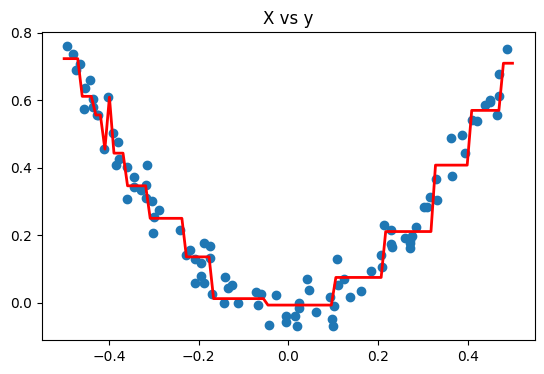

In [77]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])
plt.title('X vs y')

In [78]:
def gradient_boost(X,y,number,lr,count=1,regs=[],foo=None):

  if number == 0:
    return
  else:
    # do gradient boosting

    if count > 1:
      y = y - regs[-1].predict(X)
    else:
      foo = y

    tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    tree_reg.fit(X, y)

    regs.append(tree_reg)

    x1 = np.linspace(-0.5, 0.5, 500)
    y_pred = sum(lr * regressor.predict(x1.reshape(-1, 1)) for regressor in regs)

    print(number)
    plt.figure()
    plt.plot(x1, y_pred, linewidth=2)
    plt.plot(X[:, 0], foo,"r.")
    plt.show()

    gradient_boost(X,y,number-1,lr,count+1,regs,foo=foo)

5


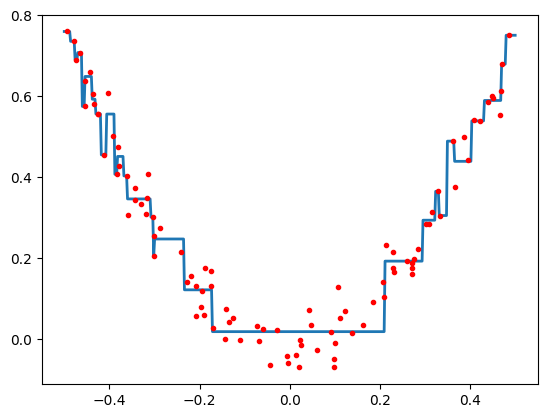

4


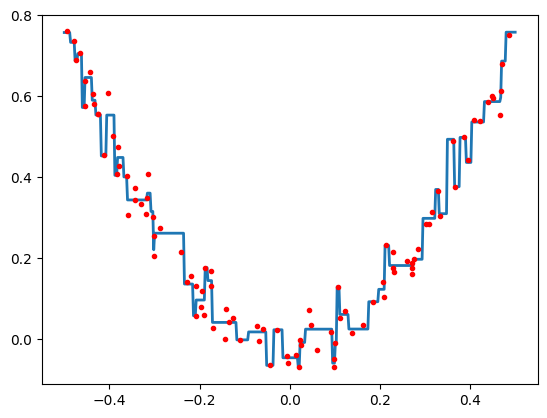

3


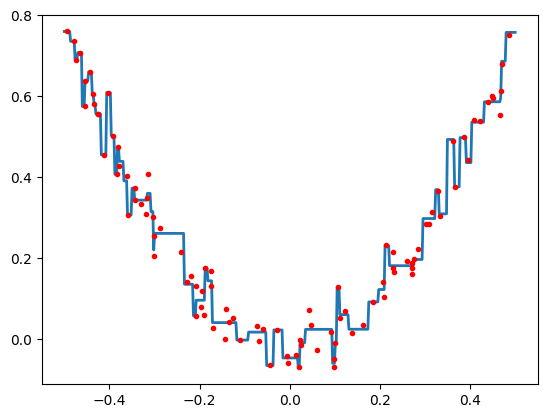

2


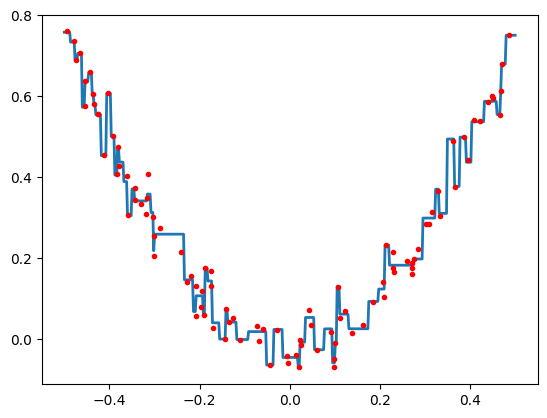

1


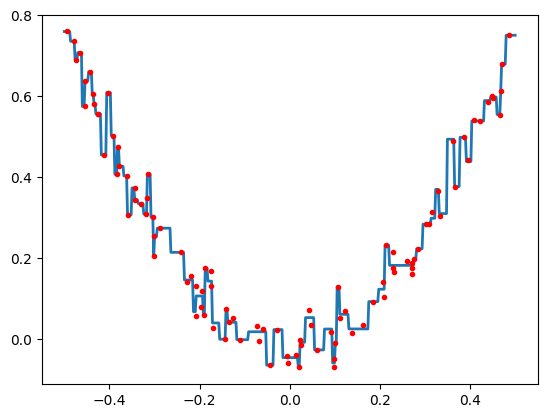

In [79]:

np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)
gradient_boost(X,y,5,lr=1)